<a href="https://colab.research.google.com/github/Kofefee/monocular-depth-estimation/blob/main/MonocularDepthEstimation_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# Prüfen, welche Umgebung Colab bereitstellt
!python --version
!nvidia-smi

Python 3.11.13
Thu Oct  1 15:10:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------------------------

In [7]:
# Repository klonen
!git clone https://github.com/lpiccinelli-eth/UniDepth.git
%cd UniDepth

# Optional: auf deinen bisherigen Commit gehen
!git checkout 04de17323981807e2354068dbcc1889a8de3ca7d

# UniDepth + Dependencies installieren
!pip install -e . --extra-index-url https://download.pytorch.org/whl/cu118

Cloning into 'UniDepth'...
remote: Enumerating objects: 625, done.
remote: Counting objects: 100% (270/270), done.
remote: Compressing objects: 100% (196/196), done.
remote: Total 625 (delta 182), reused 74 (delta 74), pack-reused 355 (from 2)
Receiving objects: 100% (625/625), 24.57 MiB | 23.74 MiB/s, done.
Resolving deltas: 100% (309/309), done.
/content/UniDepth/UniDepth
Note: switching to '04de17323981807e2354068dbcc1889a8de3ca7d'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 04de173 Remove Pytorch3D, ad

In [8]:
import torch
import numpy as np

import PIL
from PIL import Image
import matplotlib.pyplot as plt

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.version.cuda)
print("CUDA verfügbar:", torch.cuda.is_available())
print("NumPy   :", np.__version__)
print("Pillow  :", PIL.__version__)

PyTorch : 2.2.0+cu118
CUDA    : 11.8
CUDA verfügbar: True
NumPy   : 1.26.4
Pillow  : 10.2.0


In [9]:
!pip check

curl-cffi 0.12.0 has requirement certifi>=2024.2.2, but you have certifi 2022.12.7.
grpcio-status 1.71.2 has requirement protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.3.
opencv-python-headless 4.12.0.88 has requirement numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4.
thinc 8.3.6 has requirement numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4.
ydf 0.12.0 has requirement protobuf<6.0.0,>=5.29.1, but you have protobuf 4.25.3.


In [10]:
from unidepth.models import UniDepthV1, UniDepthV2

print("UniDepth erfolgreich importiert!")

/usr/local/lib/python3.11/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/content/UniDepth/UniDepth/unidepth/utils/chamfer_distance.py:9: UserWarning: !! To run evaluation you need KNN. Please compile KNN: `cd unidepth/ops/knn with && bash compile.sh`.
  warnings.warn(
This is just a warning: triton is not available


UniDepth erfolgreich importiert!


In [11]:
name = 'unidepth-v2-vitl14' # unidepth-v2-vits14, unidepth-v2-vits14
model = UniDepthV2.from_pretrained(f"lpiccinelli/{name}")

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Not loading pretrained weights for backbone
EdgeGuidedLocalSSI reverts to a non cuda-optimized operation, you will experince large slowdown, please install it:  `cd ./unidepth/ops/extract_patches && bash compile.sh`


In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device).eval()

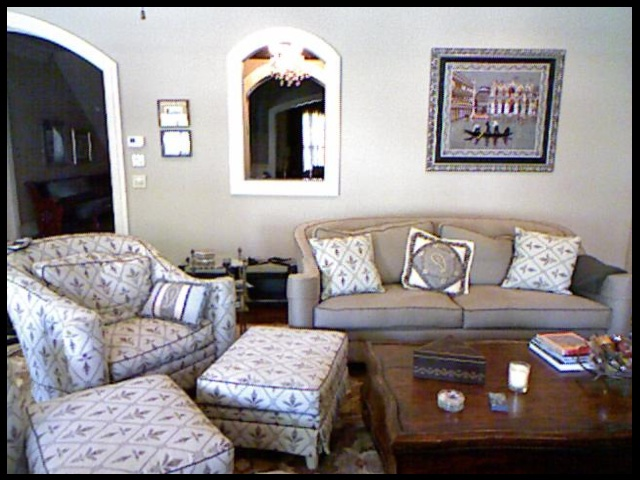

In [13]:
image_path = "assets/demo/rgb.png"
rgb_img = Image.open(image_path)

rgb_img

In [14]:
# Convert numpy array into tensor
rgb = torch.from_numpy(np.array(Image.open(image_path))).permute(2, 0, 1)

In [15]:
predictions = model.infer(rgb)
print("Keys in prediction:", predictions.keys())

/content/UniDepth/UniDepth/unidepth/models/unidepthv2/unidepthv2.py:262: UserWarning: !! self.resolution_level not set, using default bounds !!
  warnings.warn("!! self.resolution_level not set, using default bounds !!")


Keys in prediction: dict_keys(['confidence', 'intrinsics', 'radius', 'depth', 'points', 'rays', 'depth_features'])


In [16]:
#GPU
depth = predictions["depth"]
print(depth)
#CPU
depth_np = depth.squeeze().cpu().numpy()
print(depth_np)

tensor([[[[4.3224, 4.3047, 4.3079,  ..., 4.1856, 4.1785, 4.1761],
          [4.3164, 4.3030, 4.3104,  ..., 4.1879, 4.1809, 4.1784],
          [4.3194, 4.3103, 4.3172,  ..., 4.1902, 4.1873, 4.1811],
          ...,
          [1.7422, 1.7469, 1.7501,  ..., 2.0757, 2.0721, 2.0708],
          [1.7412, 1.7460, 1.7490,  ..., 2.0766, 2.0730, 2.0718],
          [1.7404, 1.7452, 1.7482,  ..., 2.0777, 2.0741, 2.0729]]]],
       device='cuda:0')
[[4.32244   4.3047    4.3079324 ... 4.18564   4.178477  4.1761403]
 [4.316391  4.302993  4.3103504 ... 4.187894  4.180852  4.1783857]
 [4.3194227 4.3102965 4.3171697 ... 4.1901646 4.1873097 4.1811433]
 ...
 [1.7421579 1.7469287 1.7500885 ... 2.0756743 2.0720847 2.070769 ]
 [1.741232  1.745998  1.7490402 ... 2.0766196 2.0730298 2.0718203]
 [1.7404155 1.7451781 1.748217  ... 2.0777297 2.0741084 2.0728989]]


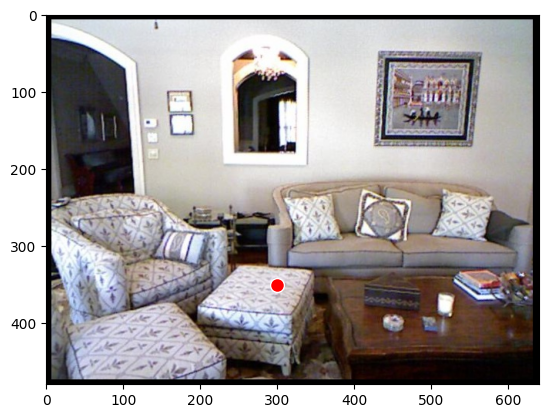

In [17]:
#Specific Pixel that we want to look deeper into
x, y = 300, 350
plt.imshow(np.array(rgb_img))
plt.scatter(x, y, s=100, c='red', marker='o', edgecolors='white')
plt.show()

In [18]:
#depth value of that specific pixel:
print("Depth value:", depth_np[y,x])

Depth value: 2.6347072


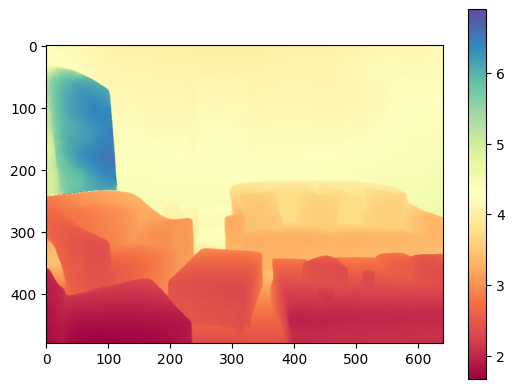

In [19]:
plt.imshow(depth_np, cmap='Spectral')
plt.colorbar()
plt.show()

In [20]:
!pip -q install open3d

In [21]:
#RGBD with data (Red, Green, Blue and Depth)
import open3d as o3d

rgbd_image = o3d.geometry.RGBDImage.create_from_color_and_depth(
    color=o3d.geometry.Image(np.array(rgb_img)),
    depth=o3d.geometry.Image(depth_np),
    depth_scale=1.0,
    depth_trunc=15.0,
    convert_rgb_to_intensity=False
)

In [22]:
#Set an estimate of the camera position. This has to be set manually or estimated. Then we can create a point cloud with the existing depth data.

#Set camera setup
width, height = rgb_img.width, rgb_img.height
intrinsic = o3d.camera.PinholeCameraIntrinsic(
    width=width,
    height=height,
    fx=525.0,  # Focal length x
    fy=525.0,  # Focal length y
    cx=width / 2,  # Principal point x
    cy=height / 2   # Principal point y
)

#Create point cloud
pcd = o3d.geometry.PointCloud.create_from_rgbd_image(
    rgbd_image,
    intrinsic
)

# Flip the point cloud to avoid upside down -> bc its from the view of the camera, so it has to be flipped bc of the coordinate system used
pcd.transform([[1, 0, 0, 0], [0, -1, 0, 0], [0, 0, -1, 0], [0, 0, 0, 1]])

points = np.asarray(pcd.points)
colors = np.asarray(pcd.colors)

o3d.io.write_point_cloud("png.ply", pcd)

True

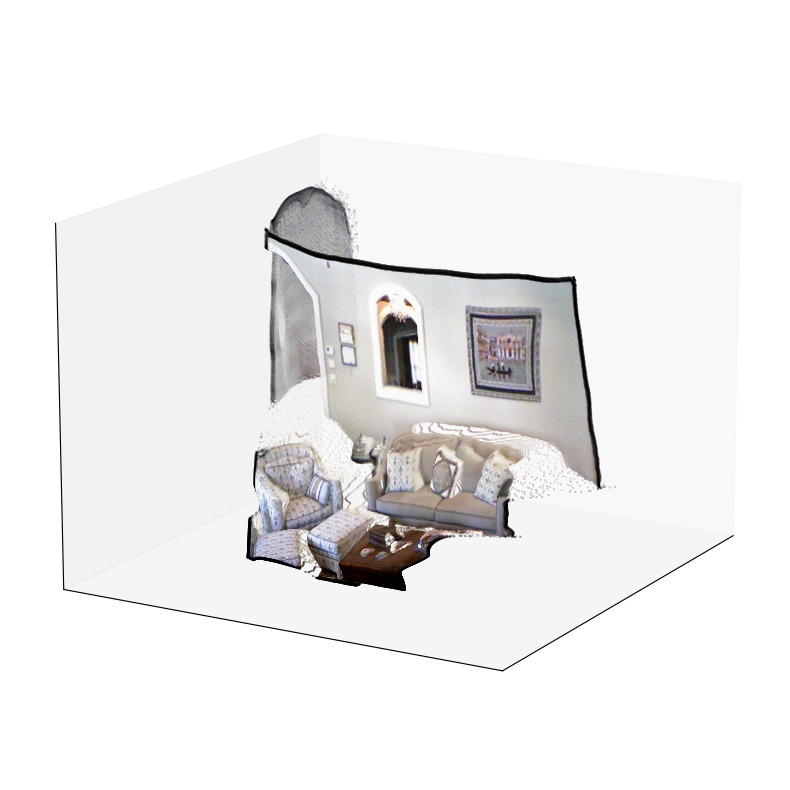

In [24]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(points[:, 2], points[:, 0], points[:, 1], c=colors, s=0.1, marker='.')

ax.view_init(elev=15, azim=30) # Change this to adjust the viewpoint
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
ax.grid(True)

plt.tight_layout()
plt.show()

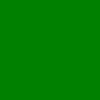

In [25]:
rect_size = (100, 100)
green_rect = Image.new('RGB', rect_size, color='green')

green_rect

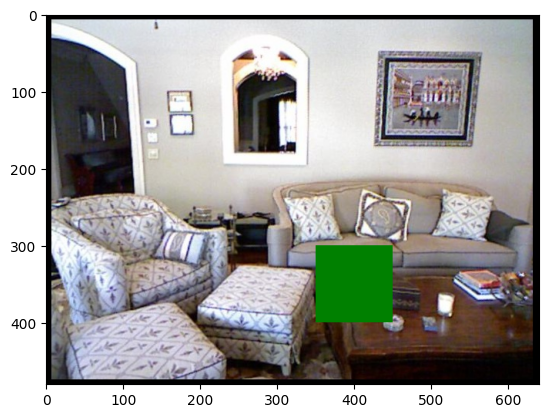

In [26]:
# Convert to numpy
rgb_np = np.array(rgb_img)
rect_np = np.array(green_rect)

# Paste rectangle to the image
rgb_np[300:400, 350:450] = rect_np

# Show the result
plt.imshow(rgb_np)
plt.show()

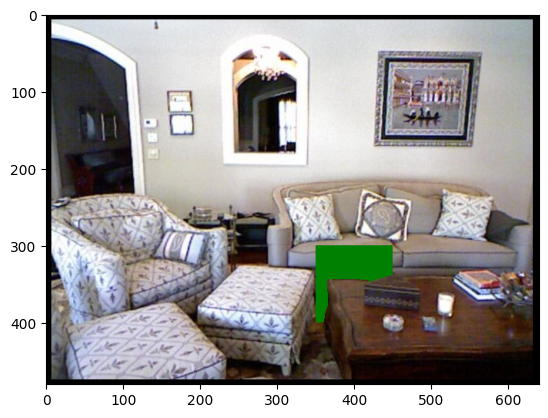

In [27]:
rgb_np = np.array(rgb_img)
rect_np = np.array(green_rect)

rect_depth = 3.0
#Settimng up a mask (is area greater then rectangles depth)
mask = depth_np[300:400, 350:450] > rect_depth
#replace only the image regions that have depth values greater than the rectangle's depth with the green rectangle
rgb_np[300:400, 350:450][mask] = rect_np[mask]

plt.imshow(rgb_np)
plt.show()

In [ ]:
#Tutorial: https://www.kaggle.com/code/patiencechewyeecheah/monocular-depth-estimation-guide-for-beginners$0